In [1]:
import sys
print(sys.executable)

c:\Users\MSI\AppData\Local\Programs\Python\Python313\python.exe


In [2]:
%pip install --upgrade pip
%pip install numpy pandas scipy scikit-learn matplotlib seaborn joblib jupyter ipykernel

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [3]:
import json
import numpy as np
import pandas as pd

from scipy.sparse import load_npz

user_item = load_npz(
    "../data/processed/interaction_matrix.npz"
).tocsr()

with open("../data/processed/mappings.json", "r") as f:
    mappings = json.load(f)

user_to_idx = mappings["user_to_idx"]
item_to_idx = mappings["item_to_idx"]

item_user = user_item.T.tocsr()

print("Matrice :", user_item.shape)
print("Utilisateurs :", len(user_to_idx))
print("Articles :", len(item_to_idx))

Matrice : (50000, 65238)
Utilisateurs : 50000
Articles : 65238


In [4]:
%pip install implicit

Note: you may need to restart the kernel to use updated packages.


In [28]:
from implicit.als import AlternatingLeastSquares

als_model = AlternatingLeastSquares(
    factors=50,
    regularization=0.1,
    iterations=15,
    random_state=42
)

als_model.fit(user_item * 20)


  0%|          | 0/15 [00:00<?, ?it/s]

In [29]:
from threadpoolctl import threadpool_limits

threadpool_limits(limits=1, user_api="blas")

In [30]:
print("Nombre d'utilisateurs :", als_model.user_factors.shape[0])
print("Nombre d'articles :", als_model.item_factors.shape[0])
print("Dimensions des facteurs :", als_model.user_factors.shape[1])

Nombre d'utilisateurs : 50000
Nombre d'articles : 65238
Dimensions des facteurs : 50


In [31]:
user_id = 0

ids, scores = als_model.recommend(
    userid=user_id,
    user_items=user_item[user_id],
    N=10,
    filter_already_liked_items=True
)

print("Top 10 des articles recommandés :")

for item_id, score in zip(ids, scores):
    print("Article :", item_id, "| Score :", score)

Top 10 des articles recommandés :
Article : 34634 | Score : 0.088429525
Article : 49438 | Score : 0.07963686
Article : 32602 | Score : 0.07713254
Article : 43693 | Score : 0.07289482
Article : 41550 | Score : 0.07199601
Article : 50170 | Score : 0.071617275
Article : 39532 | Score : 0.06889348
Article : 37363 | Score : 0.06774213
Article : 47957 | Score : 0.06652101
Article : 38337 | Score : 0.06549312


In [32]:
news_catalog = pd.read_csv(
    "../data/train/news.tsv",
    sep="\t",
    header=None,
    names=[
        "news_id",
        "category",
        "subcategory",
        "title",
        "abstract",
        "url",
        "title_entities",
        "abstract_entities"
    ]
)

In [33]:
idx_to_item = {v: k for k, v in item_to_idx.items()}

recommended = []

for item_id, score in zip(ids, scores):
    original_id = idx_to_item[item_id]

    article = news_catalog[
        news_catalog["news_id"] == original_id
    ]

    if not article.empty:
        recommended.append({
            "news_id": original_id,
            "title": article.iloc[0]["title"],
            "score": round(float(score), 4)
        })

pd.DataFrame(recommended)

,news_id,title,score
0,N54489,Fast food cashier and manager fired for refusi...,0.0884
1,N43519,Drake Has Something to Say to the ''Kids'' Who...,0.0796
2,N287,Three school workers charged in death of speci...,0.0771
3,N7821,'Monday Night Football' commentator under fire...,0.0729
4,N33619,College gymnast dies following training accide...,0.0720
5,N48046,Cincinnati Teen Arrested After Allegedly Makin...,0.0716
6,N52122,37 Years After His Wife Is Found Dead with an ...,0.0689
7,N4642,Kodak Black Sentenced to Over 3 Years in Priso...,0.0677
8,N46526,Ilhan Omar blasts Pete King as an 'Islamophobe...,0.0665
9,N56211,University of Florida student president faces ...,0.0655


In [34]:
user_history = user_item[user_id].indices

history_ids = [
    idx_to_item[i] for i in user_history
]

news_catalog[
    news_catalog["news_id"].isin(history_ids)
][["news_id", "title", "category"]]

,news_id,title,category
49765,N7800,Man fatally shot after going to check on his w...,news


In [35]:
user_counts = np.diff(user_item.indptr)

print("Nombre minimum :", user_counts.min())
print("Nombre maximum :", user_counts.max())
print("Nombre moyen :", user_counts.mean())

# Utilisateur ayant le plus d'interactions
best_user_id = np.argmax(user_counts)

print("Utilisateur sélectionné :", best_user_id)
print("Nombre d'interactions :", user_counts[best_user_id])

Nombre minimum : 1
Nombre maximum : 129
Nombre moyen : 4.68936
Utilisateur sélectionné : 25379
Nombre d'interactions : 129


In [36]:
best_user_id = 25379

ids, scores = als_model.recommend(
    best_user_id,
    user_item[best_user_id],
    N=10
)

print("Utilisateur :", best_user_id)
print("Articles recommandés :", ids)
print("Scores :", scores)

Utilisateur : 25379
Articles recommandés : [30672 44673 40456 50021 47665  8865 27811 41945 46190 26024]
Scores : [1.8711125 1.8106763 1.7079245 1.6156825 1.5661058 1.563067  1.5199745
 1.4947493 1.4509041 1.321962 ]


In [37]:
idx_to_item = {v: k for k, v in item_to_idx.items()}

recommended = []

for item_id, score in zip(ids, scores):
    original_id = idx_to_item[item_id]

    article = news_catalog[
        news_catalog["news_id"] == original_id
    ]

    if not article.empty:
        recommended.append({
            "news_id": original_id,
            "title": article.iloc[0]["title"],
            "category": article.iloc[0]["category"],
            "score": round(float(score), 4)
        })

recommendations_df = pd.DataFrame(recommended)

display(recommendations_df)


,news_id,title,category,score
0,N26376,Stocks close higher on optimism over China tra...,finance,1.8711
1,N35170,Atlanta college student Alexis Crawford was ch...,news,1.8107
2,N14184,Man cuffed for eating sandwich on train platfo...,news,1.7079
3,N27581,Amazon's $1.5 million political gambit backfir...,finance,1.6157
4,N40300,No more fire in the kitchen: Cities are bannin...,news,1.5661
5,N59272,40 Restaurant Meals You Should Never Eat After 40,health,1.5631
6,N61623,Big celebrity money moments of the last decade,entertainment,1.5200
7,N23414,FAA threatened to ground 38 Southwest Airlines...,travel,1.4947
8,N13579,Chris Paul feels he got 'stabbed in the back' ...,sports,1.4509
9,N28188,Today in History: November 12,news,1.3220


In [38]:
# Récupérer l'historique de l'utilisateur
user_history = user_item[best_user_id].indices

history_ids = [idx_to_item[i] for i in user_history]

history_df = news_catalog[
    news_catalog["news_id"].isin(history_ids)
]

# Afficher la répartition des catégories consultées
print("Catégories de l'historique :")
display(history_df["category"].value_counts())

print("Catégories recommandées :")
display(recommendations_df["category"].value_counts())

Catégories de l'historique :


category
news             68
finance          28
weather          17
lifestyle         4
entertainment     2
music             2
video             2
sports            2
movies            1
travel            1
foodanddrink      1
autos             1
Name: count, dtype: int64

Catégories recommandées :


category
news             4
finance          2
health           1
entertainment    1
travel           1
sports           1
Name: count, dtype: int64

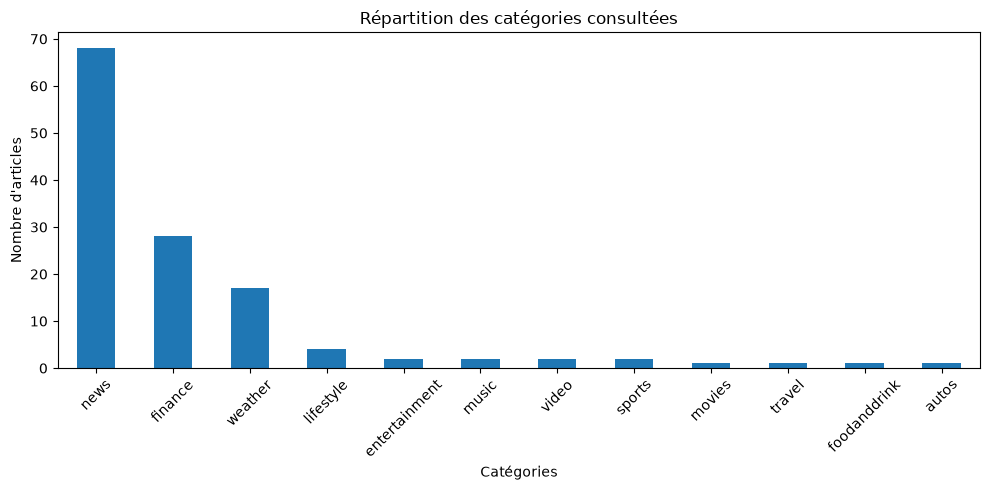

In [39]:
import matplotlib.pyplot as plt

category_counts = history_df["category"].value_counts()

plt.figure(figsize=(10, 5))
category_counts.plot(kind="bar")

plt.title("Répartition des catégories consultées")
plt.xlabel("Catégories")
plt.ylabel("Nombre d'articles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [40]:
train_interactions = pd.read_csv(
    "../data/processed/train_interactions.csv"
)

dev_impressions = pd.read_csv(
    "../data/processed/dev_impressions.csv.gz"
)

print("Colonnes train :")
print(train_interactions.columns.tolist())

print("\nAperçu train :")
display(train_interactions.head())

print("\nColonnes dev :")
print(dev_impressions.columns.tolist())

print("\nAperçu dev :")
display(dev_impressions.head())

Colonnes train :
['user_id', 'news_id']

Aperçu train :


,user_id,news_id
0,U13740,N55689
1,U91836,N17059
2,U73700,N23814
3,U34670,N49685
4,U8125,N8400



Colonnes dev :
['impression_id', 'user_id', 'time', 'impressions', 'news_id', 'label']

Aperçu dev :


,impression_id,user_id,time,impressions,news_id,label
0,1,U80234,11/15/2019 12:37:50 PM,N28682-0,N28682,0
1,1,U80234,11/15/2019 12:37:50 PM,N48740-0,N48740,0
2,1,U80234,11/15/2019 12:37:50 PM,N31958-1,N31958,1
3,1,U80234,11/15/2019 12:37:50 PM,N34130-0,N34130,0
4,1,U80234,11/15/2019 12:37:50 PM,N6916-0,N6916,0


In [41]:
# Vérifier les utilisateurs et articles présents dans les mappings

dev_users = set(dev_impressions["user_id"].unique())
dev_news = set(dev_impressions["news_id"].unique())

known_users = set(user_to_idx.keys())
known_news = set(item_to_idx.keys())

print("Nombre d'utilisateurs dans dev :", len(dev_users))
print("Utilisateurs inconnus :", len(dev_users - known_users))

print("Nombre d'articles dans dev :", len(dev_news))
print("Articles inconnus :", len(dev_news - known_news))

print("\nNombre de clics dans dev :",
      (dev_impressions["label"] == 1).sum())

print("Nombre de non-clics dans dev :",
      (dev_impressions["label"] == 0).sum())

Nombre d'utilisateurs dans dev : 50000
Utilisateurs inconnus : 44057
Nombre d'articles dans dev : 5369
Articles inconnus : 0

Nombre de clics dans dev : 111383
Nombre de non-clics dans dev : 2629615


In [42]:
print("Exemples de clés user_to_idx :")
print(list(user_to_idx.keys())[:10])

print("\nExemples d'utilisateurs dans train :")
print(train_interactions["user_id"].head(10).tolist())

print("\nExemples d'utilisateurs dans dev :")
print(dev_impressions["user_id"].head(10).tolist())

print("\nType des clés du mapping :", type(next(iter(user_to_idx.keys()))))
print("Type des user_id dans dev :", dev_impressions["user_id"].dtype)

# Comparaison des utilisateurs
train_users = set(train_interactions["user_id"].unique())
mapping_users = set(user_to_idx.keys())
validation_users = set(dev_impressions["user_id"].unique())

print("\nUtilisateurs train :", len(train_users))
print("Utilisateurs mapping :", len(mapping_users))
print("Utilisateurs communs train/mapping :", len(train_users & mapping_users))
print("Utilisateurs communs train/dev :", len(train_users & validation_users))

Exemples de clés user_to_idx :
['U100', 'U1000', 'U10001', 'U10003', 'U10008', 'U10010', 'U10011', 'U10012', 'U10014', 'U10015']

Exemples d'utilisateurs dans train :
['U13740', 'U91836', 'U73700', 'U34670', 'U8125', 'U19739', 'U19739', 'U8355', 'U46596', 'U79199']

Exemples d'utilisateurs dans dev :
['U80234', 'U80234', 'U80234', 'U80234', 'U80234', 'U80234', 'U80234', 'U80234', 'U80234', 'U80234']

Type des clés du mapping : <class 'str'>
Type des user_id dans dev : str

Utilisateurs train : 50000
Utilisateurs mapping : 50000
Utilisateurs communs train/mapping : 50000
Utilisateurs communs train/dev : 5943


In [43]:
# Garder uniquement les utilisateurs connus par ALS

known_dev = dev_impressions[
    dev_impressions["user_id"].isin(user_to_idx.keys())
].copy()

print("Utilisateurs évaluables :",
      known_dev["user_id"].nunique())

print("Nombre d'impressions évaluables :",
      len(known_dev))

print("Nombre de clics évaluables :",
      (known_dev["label"] == 1).sum())

print("Nombre de non-clics évaluables :",
      (known_dev["label"] == 0).sum())

Utilisateurs évaluables : 5943
Nombre d'impressions évaluables : 337254
Nombre de clics évaluables : 13593
Nombre de non-clics évaluables : 323661


In [44]:
# 1. Vérifier les dimensions des facteurs ALS

print("User factors :", als_model.user_factors.shape)
print("Item factors :", als_model.item_factors.shape)

# 2. Associer chaque utilisateur et article à son indice

known_dev["user_idx"] = known_dev["user_id"].map(user_to_idx)
known_dev["item_idx"] = known_dev["news_id"].map(item_to_idx)

# 3. Calculer le score ALS de chaque article présenté

user_vectors = als_model.user_factors[
    known_dev["user_idx"].to_numpy()
]

item_vectors = als_model.item_factors[
    known_dev["item_idx"].to_numpy()
]

known_dev["als_score"] = np.einsum(
    "ij,ij->i",
    user_vectors,
    item_vectors
)

# 4. Calculer Precision@10, Recall@10 et NDCG@10

def evaluate_impression(group, k=10):

    # Trier les articles selon leur score ALS
    group = group.sort_values(
        "als_score",
        ascending=False
    )

    # Labels des k premiers articles
    top_labels = group["label"].to_numpy()[:k]

    # Nombre de clics retrouvés
    hits = top_labels.sum()

    # Nombre total de clics dans cette impression
    total_relevant = group["label"].sum()

    # Precision@10
    precision = hits / k

    # Recall@10
    recall = hits / total_relevant if total_relevant > 0 else np.nan

    # NDCG@10
    discounts = np.log2(np.arange(2, len(top_labels) + 2))

    dcg = np.sum(top_labels / discounts)

    ideal_labels = np.sort(
        group["label"].to_numpy()
    )[::-1][:k]

    ideal_dcg = np.sum(ideal_labels / discounts)

    ndcg = dcg / ideal_dcg if ideal_dcg > 0 else np.nan

    return pd.Series({
        "Precision@10": precision,
        "Recall@10": recall,
        "NDCG@10": ndcg
    })


# 5. Évaluer chaque impression séparément

results = known_dev.groupby(
    ["user_id", "impression_id"]
).apply(evaluate_impression)

# 6. Moyenne des résultats

print("\nRésultats de l'évaluation ALS :")

print(
    results.mean().round(4)
)

User factors : (50000, 50)
Item factors : (65238, 50)

Résultats de l'évaluation ALS :
Precision@10    0.0686
Recall@10       0.5417
NDCG@10         0.3104
dtype: float64


In [45]:
print("Type du modèle :", type(als_model))

print("Nombre de facteurs utilisateurs :",
      als_model.user_factors.shape)

print("Nombre de facteurs articles :",
      als_model.item_factors.shape)

print("Norme des facteurs utilisateurs :",
      np.linalg.norm(als_model.user_factors))

print("Norme des facteurs articles :",
      np.linalg.norm(als_model.item_factors))

Type du modèle : <class 'implicit.cpu.als.AlternatingLeastSquares'>
Nombre de facteurs utilisateurs : (50000, 50)
Nombre de facteurs articles : (65238, 50)
Norme des facteurs utilisateurs : 296.61194
Norme des facteurs articles : 22.62322


In [47]:
train_unique_interactions = pd.read_csv(
    "../data/processed/train_interactions.csv"
)

print("Nombre d'interactions train :",
      len(train_unique_interactions))

print("Nombre d'interactions dans la matrice :",
      user_item.nnz)

print("Nombre d'utilisateurs :", len(user_to_idx))

print("Nombre d'articles :", len(item_to_idx))

print("Dimensions :", user_item.shape)

Nombre d'interactions train : 234468
Nombre d'interactions dans la matrice : 234468
Nombre d'utilisateurs : 50000
Nombre d'articles : 65238
Dimensions : (50000, 65238)


In [48]:
len(train_unique_interactions) == user_item.nnz

True

In [49]:
# Vérifier le chevauchement entre train et validation

train_pairs = set(zip(
    train_unique_interactions["user_id"],
    train_unique_interactions["news_id"]
))

dev_clicks = known_dev[known_dev["label"] == 1]

dev_pairs = set(zip(
    dev_clicks["user_id"],
    dev_clicks["news_id"]
))

overlap = train_pairs.intersection(dev_pairs)

print("Clics positifs dans dev :", len(dev_pairs))
print("Interactions communes :", len(overlap))
print("Taux de chevauchement :",
      round(len(overlap) / len(dev_pairs) * 100, 2), "%")

Clics positifs dans dev : 13509
Interactions communes : 25
Taux de chevauchement : 0.19 %


In [51]:
train_pairs_df = train_unique_interactions[
    ["user_id", "news_id"]
].drop_duplicates()

clean_dev = known_dev.merge(
    train_pairs_df.assign(in_train=True),
    on=["user_id", "news_id"],
    how="left"
)

# Supprimer uniquement les clics déjà présents dans train
clean_dev = clean_dev[
    ~((clean_dev["label"] == 1) &
      (clean_dev["in_train"].notna()))
].copy()

print("Clics avant :", known_dev["label"].sum())
print("Clics supprimés :",
      known_dev[
          (known_dev["label"] == 1) &
          (known_dev.merge(
              train_pairs_df.assign(in_train=True),
              on=["user_id", "news_id"],
              how="left")["in_train"].notna())
      ]["label"].sum())

print("Clics après :", clean_dev["label"].sum())

Clics avant : 13593
Clics supprimés : 2
Clics après : 13567


C:\Users\MSI\AppData\Local\Temp\ipykernel_20836\2480531837.py:19: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  known_dev[


In [52]:
# Identifier les paires utilisateur-article déjà présentes dans train

train_pairs = pd.MultiIndex.from_frame(
    train_unique_interactions[["user_id", "news_id"]].drop_duplicates()
)

dev_pairs = pd.MultiIndex.from_frame(
    known_dev[["user_id", "news_id"]]
)

# Repérer les clics déjà connus
in_train = dev_pairs.isin(train_pairs)

# Nettoyer les données de validation
clean_dev = known_dev.loc[
    ~((known_dev["label"].to_numpy() == 1) & in_train)
].copy()

print("Clics avant :", int(known_dev["label"].sum()))
print("Clics supprimés :", int(
    ((known_dev["label"].to_numpy() == 1) & in_train).sum()
))
print("Clics après :", int(clean_dev["label"].sum()))

Clics avant : 13593
Clics supprimés : 26
Clics après : 13567


In [53]:
results_clean = clean_dev.groupby(
    ["user_id", "impression_id"]
).apply(evaluate_impression)

print(results_clean.mean().round(4))

Precision@10    0.0683
Recall@10       0.5407
NDCG@10         0.3091
dtype: float64


In [54]:
# Calculer la couverture du catalogue

recommended_items = set()

for user_id in range(user_item.shape[0]):

    ids, scores = als_model.recommend(
        user_id,
        user_item[user_id],
        N=10
    )

    recommended_items.update(ids)

# Nombre d'articles uniques recommandés
unique_recommended = len(recommended_items)

# Nombre total d'articles
total_items = user_item.shape[1]

# Coverage
coverage = (unique_recommended / total_items) * 100

print("Articles uniques recommandés :", unique_recommended)
print("Nombre total d'articles :", total_items)
print("Coverage :", round(coverage, 2), "%")

Articles uniques recommandés : 759
Nombre total d'articles : 65238
Coverage : 1.16 %


In [55]:
import time

# Créer un nouveau modèle ALS
als_model = AlternatingLeastSquares(
    factors=50,
    regularization=0.1,
    iterations=15,
    random_state=42
)

# Début du chronométrage
start_time = time.perf_counter()

# Entraînement
als_model.fit(user_item * 20)

# Fin du chronométrage
end_time = time.perf_counter()

training_time = end_time - start_time

print("Temps d'entraînement ALS :",
      round(training_time, 2), "secondes")

  0%|          | 0/15 [00:00<?, ?it/s]

Temps d'entraînement ALS : 5.77 secondes


In [56]:
import os
import pandas as pd
from datetime import datetime

# Créer un dossier pour les résultats ALS
os.makedirs("../results/ALS", exist_ok=True)

# Récupérer les métriques
als_metrics = results_clean.mean()

# Ajouter les métriques supplémentaires si elles sont calculées
als_metrics_dict = als_metrics.to_dict()

if "coverage" in globals():
    als_metrics_dict["Coverage (%)"] = coverage

if "training_time" in globals():
    als_metrics_dict["Training Time (seconds)"] = training_time

# Créer un DataFrame
als_results = pd.DataFrame([als_metrics_dict])

# Ajouter la date et l'heure pour éviter d'écraser un ancien fichier
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Enregistrer
als_results.to_csv(
    f"../results/ALS/als_metrics_{timestamp}.csv",
    index=False
)

print("Résultats ALS enregistrés avec succès !")

Résultats ALS enregistrés avec succès !


In [57]:
recommendations_df = pd.DataFrame(recommended)

recommendations_df.to_csv(
    f"../results/ALS/als_recommendations_{timestamp}.csv",
    index=False
)

print("Recommandations ALS enregistrées !")

Recommandations ALS enregistrées !
